# Gjenkjenning av håndskrevne sifre med CNN (PyTorch)

Plan:
1. Oppsett og valg av enhet (CPU / Apple GPU)
2. Laste og se på MNIST-data
3. Definere et CNN
4. Treningsløkke
5. Evaluering

## 1. Oppsett

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Bruk Apple-GPU (MPS) hvis tilgjengelig, ellers CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "- enhet:", device)

PyTorch 2.15.0 - enhet: mps


## 2. Laste MNIST

MNIST består av 28×28 gråtonebilder av sifre (0–9): 60 000 til trening og 10 000 til test.

- `ToTensor()` gjør bildet om til en tensor med form `[1, 28, 28]` og verdier mellom 0 og 1.
- `Normalize()` trekker fra gjennomsnittet og deler på standardavviket, noe som gjør treningen mer stabil.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),  # gjennomsnitt og standardavvik for MNIST
])

train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000)

print(len(train_data), "treningsbilder,", len(test_data), "testbilder")

60000 treningsbilder, 10000 testbilder


images: torch.Size([64, 1, 28, 28])
labels: torch.Size([64])


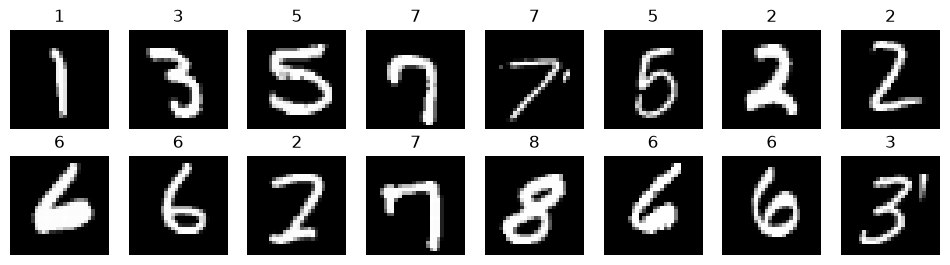

In [ ]:
# Se på én batch: hvilken form har dataene?
images, labels = next(iter(train_loader))
print("images:", images.shape)  # [batch, kanaler, høyde, bredde]
print("labels:", labels.shape)

# Visualiser noen av bildene
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, img, label in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(label.item())
    ax.axis("off")
plt.show()

## 3. Definere et CNN

Lag en klasse som arver fra `nn.Module`. Et godt utgangspunkt:

```
Conv2d(1 → 32, kernel 3) → ReLU → MaxPool2d(2)
Conv2d(32 → 64, kernel 3) → ReLU → MaxPool2d(2)
Flatten → Linear(? → 128) → ReLU → Linear(128 → 10)
```

Tips: For å finne `?`, send et testbilde gjennom konvolusjonsdelen og skriv ut `.shape`.

In [15]:
loaders = {
    "train": DataLoader(train_data, 
                        batch_size=100, 
                        shuffle=True,
                        num_workers=0),
    "test": DataLoader(test_data, 
                       batch_size=100,
                       shuffle=True,
                       num_workers=0),
}

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 32 × 14 × 14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 64 × 7 × 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# class CNN(nn.Module):
#     def __init__(self):
#         super(CNN, self).__init__()
        
#         self.conv1 = nn.Conv2d(1, 10, kernel_size=5)
#         self.conv2 = nn.Conv2d(10, 20, kernel_size=5)
#         self.conv2_drop = nn.Dropout2d()
#         # self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
#         self.fc1 = nn.Linear(320, 50)
#         self.fc2 = nn.Linear(50, 10)

#     def forward(self, x):
#         x = F.relu(F.max_pool2d(self.conv1(x), 2))
#         x = F.relu(F.max_pool2d(self.conv2_drop(self.conv2(x)), 2))
#         x = x.view(-1, 320)  # Flatten
#         x = F.relu(self.fc1(x))
#         x = F.dropout(x, training=self.training)
#         x = self.fc2(x)
        
#         return x  # Output probabilities for each class

## 4. Trening

Én epoke = én runde gjennom alle treningsbildene. For hver batch:
1. Flytt data til `device`
2. `optimizer.zero_grad()`
3. Forward: `output = model(images)`
4. `loss = F.cross_entropy(output, labels)`
5. `loss.backward()`
6. `optimizer.step()`

In [16]:
model = CNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

def train(epoch):
    model.train()
    for batch_idx, (data, target) in enumerate(loaders["train"]):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = loss_fn(output, target)
        loss.backward()
        optimizer.step()
        
        if batch_idx % 20 == 0:
            print(f"Train Epoch: {epoch} [{batch_idx * len(data)}/{len(loaders['train'].dataset)} "
                  f"({100. * batch_idx / len(loaders['train']):.0f}%)]\tLoss: {loss.item():.6f}")

def test():
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in loaders["test"]:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += loss_fn(output, target).item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(loaders["test"].dataset)

    print(f"\nTest set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(loaders['test'].dataset)} "
          f"({100. * correct / len(loaders['test'].dataset):.0f}%)\n")

for epoch in range(1, 11):
    train(epoch)
    test()

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.300653
Train Epoch: 1 [2000/60000 (3%)]	Loss: 0.467881
Train Epoch: 1 [4000/60000 (7%)]	Loss: 0.283468
Train Epoch: 1 [6000/60000 (10%)]	Loss: 0.172016
Train Epoch: 1 [8000/60000 (13%)]	Loss: 0.089549
Train Epoch: 1 [10000/60000 (17%)]	Loss: 0.119911
Train Epoch: 1 [12000/60000 (20%)]	Loss: 0.217730
Train Epoch: 1 [14000/60000 (23%)]	Loss: 0.109059
Train Epoch: 1 [16000/60000 (27%)]	Loss: 0.167450
Train Epoch: 1 [18000/60000 (30%)]	Loss: 0.048718
Train Epoch: 1 [20000/60000 (33%)]	Loss: 0.159534
Train Epoch: 1 [22000/60000 (37%)]	Loss: 0.066600
Train Epoch: 1 [24000/60000 (40%)]	Loss: 0.154015
Train Epoch: 1 [26000/60000 (43%)]	Loss: 0.115041
Train Epoch: 1 [28000/60000 (47%)]	Loss: 0.225370
Train Epoch: 1 [30000/60000 (50%)]	Loss: 0.022007
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.069394
Train Epoch: 1 [34000/60000 (57%)]	Loss: 0.104159
Train Epoch: 1 [36000/60000 (60%)]	Loss: 0.069587
Train Epoch: 1 [38000/60000 (63%)]	Loss: 0.234769
Train Epoch

In [18]:
torch.save(model.state_dict(), "mnist_cnn.pt")

## Eksport til nettsiden (ONNX)

Nettsiden i `docs/` kjører modellen direkte i nettleseren med ONNX Runtime Web. Vi pakker modellen inn slik at normalisering og softmax skjer inne i modellen. Da sender nettsiden bare inn et 28×28-bilde med verdier 0–1 og får sannsynligheter tilbake.

Kjør cellen under på nytt hver gang du har trent en ny modell.

In [17]:
import copy
import os


class DigitModelForWeb(nn.Module):
    """Modellen + normalisering + softmax, klar for nettleseren."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):                 # x: [1, 1, 28, 28], verdier 0–1, hvitt tall på svart
        x = (x - 0.1307) / 0.3081         # samme normalisering som i treningen
        return F.softmax(self.model(x), dim=1)


# Kopier til CPU, slik at modellen du trener med blir værende på GPU-en
web_model = DigitModelForWeb(copy.deepcopy(model).cpu()).eval()

os.makedirs("docs", exist_ok=True)
torch.onnx.export(
    web_model,
    (torch.rand(1, 1, 28, 28),),
    "docs/mnist_cnn.onnx",
    input_names=["image"],
    output_names=["probs"],
    external_data=False,                  # alle vektene i én fil
)
print("Lagret docs/mnist_cnn.onnx,", os.path.getsize("docs/mnist_cnn.onnx") // 1024, "kB")

[torch.onnx] Obtain model graph for `DigitModelForWeb([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DigitModelForWeb([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Lagret docs/mnist_cnn.onnx, 1855 kB


## 5. Evaluering

Kjør modellen på testdataene med `model.eval()` og `torch.no_grad()`, og regn ut nøyaktigheten. Målet er over 98 %.

In [19]:
model.eval()
torch.no_grad()  # Deaktiverer gradientberegning for å spare minne og beregningstid